In [68]:
import pandas as pd
import numpy as np

# load a dataset
df = pd.read_excel(r"c:\Users\emab6\Documents\ironhack 2026\mini_proyectos\GSAF5.xls")
df.head()


,Date,Year,Type,Country,State,Location,Activity,Name,Sex,Age,...,Species,Source,pdf,href formula,href,Case Number,Case Number.1,original order,Unnamed: 21,Unnamed: 22
0,18th September,2026.0,Unprovoked,Australia,Western Australia,Sorrento Beach Perth,Swimming,Greg O'Neil,M,63,...,Great White Shark 6m (20ft),Keith Cowley: Kevin McMurray Trackingsharks.co...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,16th September,2026.0,Unprovoked,Canada,Quebec,Off the coast of Perce Le Bilbo dive site,Diving,Unknown Male,M,?,...,Great White Shark,Keith Cowley: Kevin McMurray Trackingsharks.co...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,14th September,2026.0,Unprovoked,Bahamas,Bimini,Bimini Island,Swimming,Unknown Austrian Tourist,F,37,...,Unknown,Kevin McMurray Trackingsharks.com: Keith Cowley,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,13th September,2026.0,Unprovoked,Australia,Western Australia,Geraldton,Surfing,Mel Ismail,M,50's,...,Unknown,Simon De Marchi,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,7th September,2026.0,Unprovoked,USA,Hawaii,Honolulu,Surfing,Wants to remain anonymous,M,24,...,Tiger Shark suspected,Keith Cowley,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [69]:
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

print("\nColumn names:")
print(df.columns.tolist())

Rows: 7125
Columns: 23

Column names:
['Date', 'Year', 'Type', 'Country', 'State', 'Location', 'Activity', 'Name', 'Sex', 'Age', 'Injury', 'Fatal Y/N', 'Time', 'Species ', 'Source', 'pdf', 'href formula', 'href', 'Case Number', 'Case Number.1', 'original order', 'Unnamed: 21', 'Unnamed: 22']


In [70]:
df = df.loc[:, :"Source"].copy()

In [71]:
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")
df.head()

Rows: 7125
Columns: 15


,Date,Year,Type,Country,State,Location,Activity,Name,Sex,Age,Injury,Fatal Y/N,Time,Species,Source
0,18th September,2026.0,Unprovoked,Australia,Western Australia,Sorrento Beach Perth,Swimming,Greg O'Neil,M,63,Body not recovered,Y,1015hrs,Great White Shark 6m (20ft),Keith Cowley: Kevin McMurray Trackingsharks.co...
1,16th September,2026.0,Unprovoked,Canada,Quebec,Off the coast of Perce Le Bilbo dive site,Diving,Unknown Male,M,?,Injuries to chest shoulder and back,N,1030hrs,Great White Shark,Keith Cowley: Kevin McMurray Trackingsharks.co...
2,14th September,2026.0,Unprovoked,Bahamas,Bimini,Bimini Island,Swimming,Unknown Austrian Tourist,F,37,Serious injuries to right ankle,N,1730hrs,Unknown,Kevin McMurray Trackingsharks.com: Keith Cowley
3,13th September,2026.0,Unprovoked,Australia,Western Australia,Geraldton,Surfing,Mel Ismail,M,50's,Foot lost in attack,N,0945hrs,Unknown,Simon De Marchi
4,7th September,2026.0,Unprovoked,USA,Hawaii,Honolulu,Surfing,Wants to remain anonymous,M,24,Scrapes on inside of legs,N,1640hrs,Tiger Shark suspected,Keith Cowley


First, we load the Excel file using pandas and examine its dimensions and column names to understand the structure of the dataset. Initially, it contained 7,125 rows and 23 columns.

Following this review, we remove the eight columns that appear after "Source," as they do not provide information relevant to the objectives of our analysis. Furthermore, many of them contain a large number of null values, and some are entirely empty.

As a result, we obtain a working dataset consisting of 7,125 rows and 15 columns, while retaining all the original records. Next, we will examine the content and quality of the remaining columns to determine which ones are needed and what cleaning techniques should be applied before beginning the analysis.

In [72]:
# Keep a backup before making further changes
df_backup = df.copy()

# Remove leading and trailing spaces from column names
df.columns = df.columns.str.strip()

# Define the columns to remove
columns_to_drop = [
    "Location",
    "Name",
    "Fatal Y/N",
    "Time",
    "Species",
    "Source",
]

# Remove the selected columns
df = df.drop(columns=columns_to_drop)

# Check the resulting dimensions and column names
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")
print(df.columns.tolist())

Rows: 7125
Columns: 9
['Date', 'Year', 'Type', 'Country', 'State', 'Activity', 'Sex', 'Age', 'Injury']


In [73]:
df.dtypes

Date         object
Year        float64
Type            str
Country         str
State           str
Activity        str
Sex             str
Age          object
Injury          str
dtype: object

We have selected the relevant columns to help guide our proposal for protective sportswear for surfers. We have retained information regarding time, geography, activity, individual profiles, and injuries.

We have removed the `Location`, `Name`, `Fatal Y/N`, `Time`, `Species`, and `Source` columns, as they will not be used to address the questions in this analysis. Before removing them, we created a backup copy to preserve the data, allowing us to consult the original sources if necessary.

Following this selection, the dataset contains **7,125 rows and 9 columns**. The next step will be to review the values, resolve inconsistencies, and identify records related to surfing. Subsequently, we will analyze where the recorded incidents are concentrated to help determine the areas in which to offer our products.

In [74]:
# Summarize missing values by column
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": df.isna().mean().mul(100).round(2)
})

missing_summary = missing_summary.sort_values(
    by="missing_count",
    ascending=False
)

display(missing_summary)

,missing_count,missing_percentage
Age,2994,42.02
Activity,583,8.18
Sex,578,8.11
State,487,6.84
Country,50,0.70
Injury,36,0.51
Type,18,0.25
Year,2,0.03
Date,0,0.00


In [75]:
# Count rows with no information in any column
empty_rows = df.isna().all(axis=1).sum()

print(f"Completely empty rows: {empty_rows}")

Completely empty rows: 0


The initial review shows that there are no entirely null rows, although there are missing values ​​in several columns. The `Age` column has the highest percentage of null values ​​(42.02%), followed by `Activity` (8.18%).

For now, we are retaining these records, as the absence of information in one column does not preclude their use for other analyses.

Next, we will examine the values ​​in the `Activity` column to identify how surfing is recorded and to define the filter for our study. Once this subset has been selected, we will re-evaluate the null values ​​to determine how to handle them.

In [76]:
# Create a temporary standardized version for comparison
activity = df["Activity"].astype("string").str.strip().str.lower()

# Identify descriptions mentioning surfing or a surfboard
surf_match = activity.str.contains(
    r"\bsurfing\b|\bsurfng\b|\bsurfboard\b",
    na=False
)

# Flag other activities and ambiguous descriptions
needs_review = activity.str.contains(
    r"body|boogie|wind|kite|ski|foil|fish|div|swim|carrying|towing|\bor\b|/|\?",
    na=False
)

# Group likely surfing records while preserving the original descriptions
df["Activity_group"] = "Other / review"
df.loc[surf_match & ~needs_review, "Activity_group"] = "Surfing"

# Check the group sizes
display(df["Activity_group"].value_counts())

Activity_group
Other / review    5903
Surfing           1222
Name: count, dtype: int64

In [77]:
# Keep a backup before filtering
df_before_surf_filter = df.copy()

# Keep only records classified as surfing
df = df.loc[df["Activity_group"] == "Surfing"].copy()

# Reset the row index after filtering
df = df.reset_index(drop=True)

# Check the filtered dataset
print(f"Rows kept: {len(df)}")
print(f"Rows excluded: {len(df_before_surf_filter) - len(df)}")

display(df.head())

Rows kept: 1222
Rows excluded: 5903


,Date,Year,Type,Country,State,Activity,Sex,Age,Injury,Activity_group
0,13th September,2026.0,Unprovoked,Australia,Western Australia,Surfing,M,50's,Foot lost in attack,Surfing
1,7th September,2026.0,Unprovoked,USA,Hawaii,Surfing,M,24,Scrapes on inside of legs,Surfing
2,2nd September,2026.0,Unprovoked,USA,Florida,Surfing,M,?,Injury to right foot,Surfing
3,26th August,2026.0,Unprovoked,USA,Hawaii,Surfing,F,?,No injury bump to surfboard,Surfing
4,31st May,2026.0,Unprovoked,Australia,NSW,Surfing,M,20,Bite wounds to right foot,Surfing


In [80]:
df["Age"].unique()


array(["50's", '24', '?', '20', '38', '16', '30+', '39', '11', '27', '26',
       '13', '50+', '57', '9', '18', '40', '42', '37', 37, 28, 61, 27, 16,
       23, 41, 49, 26, nan, '64', '15', '55', '30', '50', '52', '45',
       '30s', '44', '22', '20s', '21', '46', '50s', '58', '32', '60',
       '17', '31', 14, 32, 20, 18, '40s', 25, 38, '!6', 31, 35, 58, 59,
       64, 52, 19, 17, 56, 29, 13, 15, 46, 12, 54, 22, 60, 9, 30, 40, 21,
       "20's", 50, 36, 48, 24, 42, 39, '60s', 45, 62, 33, 65, 43, 11, 47,
       34, '23', '47', '41', '35', '34', '29', '28', '51', '14', '43',
       '12', '19', '25', '10', '48', '61', '53', '63', '49', '33', 'Teen',
       '68', '54', 'teen', '36', 44, 57, 51, '30 or 36', '33 or 37', '6',
       10, ' 28', 'young'], dtype=object)

In [81]:
df["Age_numeric"] = pd.to_numeric(df["Age"], errors="coerce")

In [82]:
# Flag ages outside the working range for review
age_for_grouping = df["Age_numeric"].where(df["Age_numeric"].between(0, 120))

# Define age intervals and category labels
age_bins = [0, 13, 18, 30, 45, 60, float("inf")]

age_labels = [
    "Children (0-12)",
    "Teens (13-17)",
    "Young adults (18-29)",
    "Adults (30-44)",
    "Middle-aged adults (45-59)",
    "Older adults (60+)"
]

# Create age groups using lower-inclusive intervals
df["Age_group"] = pd.cut(
    age_for_grouping,
    bins=age_bins,
    labels=age_labels,
    right=False
)

# Keep missing and flagged ages in a separate category
df["Age_group"] = (
    df["Age_group"]
    .cat.add_categories(["Unknown / review"])
    .fillna("Unknown / review")
)

# Count records in each age group
display(df["Age_group"].value_counts(sort=False))

Age_group
Children (0-12)                26
Teens (13-17)                 215
Young adults (18-29)          407
Adults (30-44)                200
Middle-aged adults (45-59)     83
Older adults (60+)             14
Unknown / review              277
Name: count, dtype: int64

In [83]:
# Keep a backup before excluding unknown age groups
df_before_age_filter = df.copy()

# Remove records with unknown or flagged ages
df = df.loc[df["Age_group"] != "Unknown / review"].copy()
df = df.reset_index(drop=True)

# Remove the unused category
df["Age_group"] = df["Age_group"].cat.remove_unused_categories()

# Check the remaining age groups
print(f"Remaining rows: {len(df)}")
display(df["Age_group"].value_counts(sort=False))

Remaining rows: 945


Age_group
Children (0-12)                26
Teens (13-17)                 215
Young adults (18-29)          407
Adults (30-44)                200
Middle-aged adults (45-59)     83
Older adults (60+)             14
Name: count, dtype: int64

In [84]:
df["Date"].unique()

array(['7th September', '31st May', '30th May', '3rd April', '18th March',
       '20th January', '19th January', '13th January', '4th November',
       '6th September', '7th August', '18th July', '6th July',
       datetime.datetime(2025, 3, 10, 0, 0),
       datetime.datetime(2025, 1, 22, 0, 0),
       datetime.datetime(2025, 1, 2, 0, 0),
       datetime.datetime(2024, 11, 1, 0, 0),
       datetime.datetime(2024, 10, 25, 0, 0),
       datetime.datetime(2024, 10, 11, 0, 0),
       datetime.datetime(2024, 7, 23, 0, 0),
       datetime.datetime(2024, 7, 18, 0, 0),
       datetime.datetime(2024, 6, 23, 0, 0),
       datetime.datetime(2024, 4, 20, 0, 0), '09-Jan-2024', '30 Dec-2023',
       '28 Dec-2023', '25 Dec-2023', '31 Oct-2023', '25 Oct 2023',
       '15 Oct 2023', '13 Oct-2023', '02 Oct-2023', '12 Sep-2023',
       '25 Aug 2023', '31 Jul-2023', '14 Jul-2023', '03 Jul-2023',
       '21-May 2023', '13-May-2023', '22-Apr-2023', '09-Apr-2023',
       '21-Feb-2023', '19-Feb-2023', '06-O

In [85]:
# Convert year values to numbers for filtering
year_numeric = pd.to_numeric(df["Year"], errors="coerce")

# Select five calendar years, including the current year
start_year = 2006
end_year = 2026

df_recent = df.loc[
    year_numeric.between(start_year, end_year)
].copy()

# Store the selected years as nullable integers
df_recent["Year"] = year_numeric.loc[df_recent.index].astype("Int64")

# Check the selected period and record counts
print(f"Rows in selected period: {len(df_recent)}")
print(f"Records with missing or unrecognized year: {year_numeric.isna().sum()}")

display(df_recent["Year"].value_counts().sort_index())

Rows in selected period: 495
Records with missing or unrecognized year: 0


Year
2006    26
2007    30
2008    36
2009    28
2010    22
2011    29
2012    39
2013    22
2014    26
2015    38
2016    32
2017    29
2018    20
2019    24
2020    24
2021    16
2022     9
2023    19
2024     8
2025     9
2026     9
Name: count, dtype: Int64

In [41]:
# Count records by country in the selected period
display(df_recent["Country"].value_counts(dropna=False))

# Show the ten most frequent country and state combinations
location_counts = (
    df_recent.groupby(["Country", "State"], dropna=False)
    .size()
    .reset_index(name="incident_count")
    .sort_values("incident_count", ascending=False)
)

display(location_counts.head(10))

Country
USA                                      285
AUSTRALIA                                115
SOUTH AFRICA                              23
Australia                                 14
REUNION                                   11
BRAZIL                                    10
NEW ZEALAND                                7
ECUADOR                                    4
MEXICO                                     4
JAPAN                                      3
INDONESIA                                  3
FRENCH POLYNESIA                           2
COSTA RICA                                 2
NEW CALEDONIA                              2
Samoa                                      1
Hawaii                                     1
REUNION ISLAND                             1
NaN                                        1
ST HELENA, British overseas territory      1
UNITED KINGDOM                             1
CANADA                                     1
SCOTLAND                                   1
UN

,Country,State,incident_count
53,USA,Florida,176
0,AUSTRALIA,New South Wales,68
55,USA,Hawaii,37
52,USA,California,34
6,AUSTRALIA,Western Australia,20
47,SOUTH AFRICA,Western Cape Province,12
46,SOUTH AFRICA,Eastern Cape Province,11
58,USA,North Carolina,11
5,AUSTRALIA,Victoria,10
3,AUSTRALIA,South Australia,9


In [42]:
# Create a working copy for geographic cleaning
df_geo = df_recent.copy()

# Standardize country names
df_geo["Country"] = (
    df_geo["Country"]
    .astype("string")
    .str.strip()
    .str.title()
    .replace({"Usa": "USA"})
)

# Remove surrounding spaces from state names
df_geo["State"] = df_geo["State"].astype("string").str.strip()

# Expand Australian state abbreviations
australia_mask = df_geo["Country"].eq("Australia")

df_geo.loc[australia_mask, "State"] = (
    df_geo.loc[australia_mask, "State"]
    .replace({
        "NSW": "New South Wales",
        "WA": "Western Australia"
    })
)

# Recalculate country and state counts
display(df_geo["Country"].value_counts(dropna=False))

display(
    df_geo.groupby(["Country", "State"], dropna=False)
    .size()
    .reset_index(name="incident_count")
    .sort_values("incident_count", ascending=False)
)

Country
USA                                      285
Australia                                129
South Africa                              23
Reunion                                   11
Brazil                                    10
New Zealand                                7
Ecuador                                    4
Mexico                                     4
Japan                                      3
Indonesia                                  3
French Polynesia                           2
Costa Rica                                 2
New Caledonia                              2
Samoa                                      1
Hawaii                                     1
Reunion Island                             1
<NA>                                       1
St Helena, British Overseas Territory      1
United Kingdom                             1
Canada                                     1
Scotland                                   1
United Arab Emirates (Uae)                 1
Fi

,Country,State,incident_count
45,USA,Florida,176
0,Australia,New South Wales,77
47,USA,Hawaii,37
44,USA,California,34
5,Australia,Western Australia,24
42,South Africa,Western Cape Province,12
41,South Africa,Eastern Cape Province,11
50,USA,North Carolina,11
2,Australia,South Australia,11
4,Australia,Victoria,10


In [43]:
# Check dataset sizes and the actual year range
years = pd.to_numeric(df_geo["Year"], errors="coerce")

print(f"Rows before geographic cleaning: {len(df_recent)}")
print(f"Rows after geographic cleaning: {len(df_geo)}")
print(f"Earliest year: {years.min()}")
print(f"Latest year: {years.max()}")

# Check the distribution by year
display(years.value_counts().sort_index())

Rows before geographic cleaning: 495
Rows after geographic cleaning: 495
Earliest year: 2006
Latest year: 2026


Year
2006    26
2007    30
2008    36
2009    28
2010    22
2011    29
2012    39
2013    22
2014    26
2015    38
2016    32
2017    29
2018    20
2019    24
2020    24
2021    16
2022     9
2023    19
2024     8
2025     9
2026     9
Name: count, dtype: Int64

In [44]:
# Correct the previously verified Hawaii and Maui record
hawaii_mask = (
    df_geo["Country"].eq("Hawaii")
    & df_geo["State"].eq("Maui")
)

df_geo.loc[hawaii_mask, ["Country", "State"]] = ["USA", "Hawaii"]

# Inspect remaining geographic categories that need review
display(
    df_geo.loc[
        df_geo["Country"].isin(
            ["Reunion", "Reunion Island", "Scotland"]
        ),
        ["Country", "State"]
    ]
)

,Country,State
111,Reunion Island,<NA>
185,Reunion,<NA>
223,Reunion,<NA>
229,Reunion,Le Port
232,Reunion,Saint-Gilles-les-Bains
251,Reunion,Saint-Leu
301,Reunion,Saint Leu
305,Reunion,Trois-Bassins
332,Scotland,Moray
343,Reunion,Saint-Gilles


In [45]:
# Standardize equivalent country and territory labels
df_geo["Country"] = df_geo["Country"].replace({
    "Reunion Island": "Reunion",
    "Scotland": "United Kingdom"
})

# Standardize confirmed spelling variants within Reunion
reunion_mask = df_geo["Country"].eq("Reunion")

df_geo.loc[reunion_mask, "State"] = (
    df_geo.loc[reunion_mask, "State"]
    .replace({
        "Saint Leu": "Saint-Leu",
        "Saint Gilles": "Saint-Gilles"
    })
)

# Check the final country counts
print(f"Total records: {len(df_geo)}")
display(df_geo["Country"].value_counts(dropna=False))

# Recalculate the most frequent geographic combinations
location_counts = (
    df_geo.groupby(["Country", "State"], dropna=False)
    .size()
    .reset_index(name="incident_count")
    .sort_values("incident_count", ascending=False)
)

display(location_counts.head(10))

Total records: 495


Country
USA                                      286
Australia                                129
South Africa                              23
Reunion                                   12
Brazil                                    10
New Zealand                                7
Ecuador                                    4
Mexico                                     4
Japan                                      3
Indonesia                                  3
French Polynesia                           2
United Kingdom                             2
Costa Rica                                 2
New Caledonia                              2
Samoa                                      1
<NA>                                       1
St Helena, British Overseas Territory      1
Canada                                     1
United Arab Emirates (Uae)                 1
Fiji                                       1
Name: count, dtype: Int64

,Country,State,incident_count
40,USA,Florida,176
0,Australia,New South Wales,77
42,USA,Hawaii,38
39,USA,California,34
5,Australia,Western Australia,24
37,South Africa,Western Cape Province,12
2,Australia,South Australia,11
36,South Africa,Eastern Cape Province,11
45,USA,North Carolina,11
4,Australia,Victoria,10


We selected the records related to surfing, converted the ages to numbers, and grouped them into categories, excluding unknown or unusable ages. We then filtered the data for the period **2006–2026** and standardized the geographic locations, resulting in **495 records**.

**The United States accounts for 286 records and Australia for 129**, together comprising **83.8% of the sample**. The locations with the most records are **Florida (176), New South Wales (77), Hawaii (38), and California (34)**.

These results allow us to prioritize these locations for investigating potential markets for our protective clothing for surfers. However, the counts alone do not indicate higher individual risk or commercial demand.

The conclusions apply to the filtered sample: they exclude cases without a usable age, include one record with an unidentified country, and consider **2026 to be incomplete**.



In [46]:
# Inspect the most frequent injury descriptions
display(df_geo["Injury"].value_counts(dropna=False).head(50))

Injury
FATAL                                        30
Foot bitten                                  16
Lacerations to left foot                     11
Left foot bitten                             10
Lacerations to foot                           9
No injury, surfboard bitten                   6
Lacerations to right foot                     6
No injury, board bitten                       6
Minor injury to foot                          5
No injury, shark bit surfboard                5
Lacerations to right hand                     5
Right foot bitten                             5
No injury, board damaged                      4
No injury                                     4
Leg bitten                                    3
Lacerations to leg                            3
Calf bitten                                   3
Lacerations to hand                           3
Lacerations to right leg                      2
Both feet bitten                              2
Puncture wounds to foot          

In [47]:
# Standardize injury descriptions for comparison
injury_text = (
    df_geo["Injury"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# Leave unclassified descriptions pending review
df_geo["Injury_status"] = "Review"

# Identify the explicit fatal label
fatal_mask = injury_text.eq("fatal").fillna(False)
df_geo.loc[fatal_mask, "Injury_status"] = "Fatal reported"

# Identify descriptions explicitly reporting no injury
no_injury_mask = injury_text.str.contains(
    r"\bno injur(?:y|ies)\b|\buninjured\b|\bnone sustained\b",
    na=False
)
df_geo.loc[no_injury_mask & ~fatal_mask, "Injury_status"] = (
    "No injury reported"
)

# Compare the provisional categories by country
display(
    pd.crosstab(
        df_geo["Country"].fillna("Unknown"),
        df_geo["Injury_status"]
    )
)

Injury_status,Fatal reported,No injury reported,Review
Country,,,
Australia,15,24,90
Brazil,0,0,10
Canada,0,0,1
Costa Rica,1,0,1
Ecuador,0,0,4
Fiji,0,0,1
French Polynesia,0,1,1
Indonesia,0,0,3
Japan,0,0,3


In [48]:
# Inspect the most frequent injury descriptions pending review
review_counts = (
    df_geo.loc[df_geo["Injury_status"].eq("Review"), "Injury"]
    .value_counts(dropna=False)
)

with pd.option_context("display.max_colwidth", None):
    display(review_counts.head(15))

Injury
Foot bitten                  16
Lacerations to left foot     11
Left foot bitten             10
Lacerations to foot           9
Lacerations to right foot     6
Minor injury to foot          5
Lacerations to right hand     5
Right foot bitten             5
Leg bitten                    3
Lacerations to leg            3
Calf bitten                   3
Lacerations to hand           3
Lacerations to right leg      2
Both feet bitten              2
Puncture wounds to foot       2
Name: count, dtype: int64

In [49]:
# Exclude records already identified as reporting no injury
injury_text = (
    df_geo.loc[
        df_geo["Injury_status"].ne("No injury reported"),
        "Injury"
    ]
    .astype("string")
    .str.lower()
)

# Define keywords for each body area
body_patterns = {
    "Feet / ankles": r"\b(?:foot|feet|toes?|heels?|ankles?)\b",
    "Legs": r"\b(?:legs?|calf|calves|thighs?|knees?|shins?)\b",
    "Hands / wrists": r"\b(?:hands?|fingers?|wrists?)\b",
    "Arms / shoulders": r"\b(?:arms?|forearms?|elbows?|shoulders?)\b",
    "Torso": r"\b(?:torso|chest|abdomen|stomach|back|buttocks?)\b",
    "Head / neck": r"\b(?:head|neck|face|scalp)\b"
}

# Count records mentioning each body area
body_area_counts = pd.Series({
    area: injury_text.str.contains(pattern, na=False).sum()
    for area, pattern in body_patterns.items()
})

display(
    body_area_counts
    .sort_values(ascending=False)
    .to_frame(name="records_mentioning_area")
)

,records_mentioning_area
Feet / ankles,176
Legs,142
Hands / wrists,63
Arms / shoulders,44
Torso,13
Head / neck,5


To date, we have analyzed 495 records of surfing-related incidents between 2006 and 2026, after selecting cases with usable age data and standardizing the locations.

The United States accounts for 286 records, and Australia for 129. However, frequency does not indicate severity: we found 30 records labeled as FATAL, 61 indicating no injuries, and 404 pending classification.

In the descriptions analyzed—excluding cases identified as having no injury—mentions of feet and ankles (176 records) and legs (142) stand out. These results guide research into lower-limb protection, although they do not demonstrate the effectiveness of any specific garment.

The counts by body region may overlap and require further review. Additionally, the sample excludes ineligible age groups, and 2,026 records are incomplete.

The next step will be to compare the body regions mentioned by country to determine whether the needs described vary across the locations of interest.



In [50]:
# Prepare country labels and injury descriptions
countries = df_geo["Country"].fillna("Unknown")
injury_text = df_geo["Injury"].astype("string").str.lower()

# Exclude records explicitly classified as reporting no injury
eligible = df_geo["Injury_status"].ne("No injury reported")

# Identify body areas mentioned in each record
body_mentions = pd.DataFrame({
    area: injury_text.str.contains(pattern, na=False) & eligible
    for area, pattern in body_patterns.items()
})

# Count mentions by country and body area
country_totals = countries.value_counts()

country_area_counts = (
    body_mentions.groupby(countries)
    .sum()
    .astype(int)
    .reindex(country_totals.index)
)

# Calculate percentages using all selected records from each country
country_area_percentages = (
    country_area_counts
    .div(country_totals, axis=0)
    .mul(100)
    .round(1)
)

# Display the ten countries with the most selected records
print("Body area mentions by country:")
display(country_area_counts.head(10))

print("Percentage of each country's records mentioning each area:")
display(country_area_percentages.head(10))

Body area mentions by country:


,Feet / ankles,Legs,Hands / wrists,Arms / shoulders,Torso,Head / neck
Country,,,,,,
USA,137,64,36,17,4,2
Australia,24,45,14,17,6,1
South Africa,3,13,0,1,2,0
Reunion,3,2,2,3,0,0
Brazil,3,6,1,1,0,1
New Zealand,1,2,3,1,0,1
Ecuador,0,4,1,0,0,0
Mexico,0,2,1,1,0,0
Japan,1,1,0,1,0,0


Percentage of each country's records mentioning each area:


,Feet / ankles,Legs,Hands / wrists,Arms / shoulders,Torso,Head / neck
Country,,,,,,
USA,47.9,22.4,12.6,5.9,1.4,0.7
Australia,18.6,34.9,10.9,13.2,4.7,0.8
South Africa,13.0,56.5,0.0,4.3,8.7,0.0
Reunion,25.0,16.7,16.7,25.0,0.0,0.0
Brazil,30.0,60.0,10.0,10.0,0.0,10.0
New Zealand,14.3,28.6,42.9,14.3,0.0,14.3
Ecuador,0.0,100.0,25.0,0.0,0.0,0.0
Mexico,0.0,50.0,25.0,25.0,0.0,0.0
Japan,33.3,33.3,0.0,33.3,0.0,0.0


In [53]:
# Install matplotlib in the current notebook environment
%pip install matplotlib

   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ---------------------------------------- 9.3/9.3 MB 79.3 MB/s  0:00:00
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 93.1 MB/s  0:00:00
   ---------------------------------------- 0.0/7.3 MB ? eta -:--:--
   ---------------------------------------- 7.3/7.3 MB 101.9 MB/s  0:00:00

   ---------------------------------------- 0/7 [pyparsing]
   ----- ---------------------------------- 1/7 [pillow]
   ----- ---------------------------------- 1/7 [pillow]
   ----- ---------------------------------- 1/7 [pillow]
   ----- ---------------------------------- 1/7 [pillow]
   ----- ---------------------------------- 1/7 [pillow]
   ----- ---------------------------------- 1/7 [pillow]
   ----- ---------------------------------- 1/7 [pillow]
   ----------------- ---------------------- 3/7 [fonttools]
   ----------------- ---------------------- 3/7 [f

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


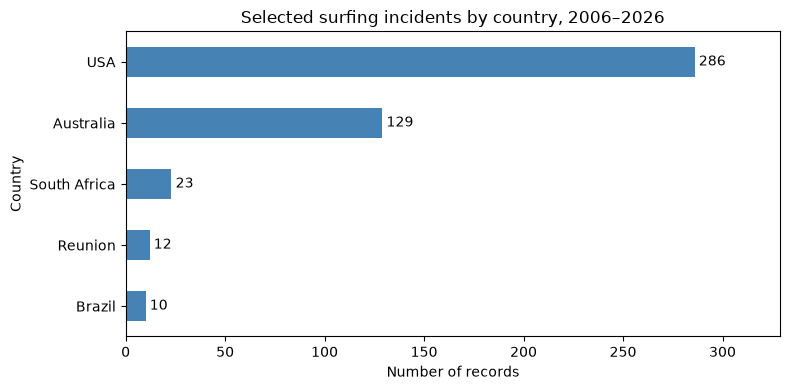

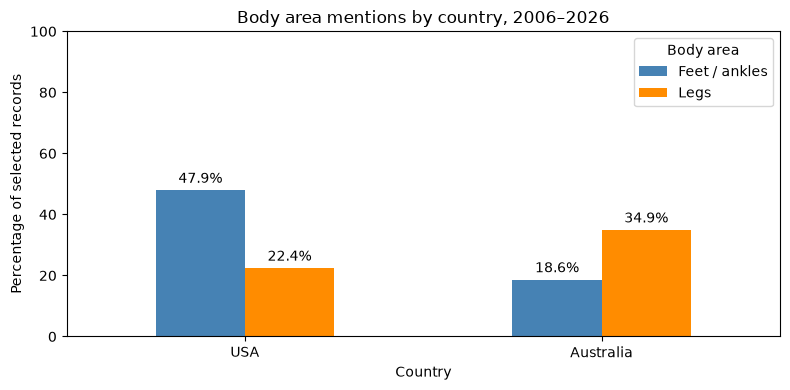

In [54]:
import matplotlib.pyplot as plt

# Plot the five countries with the most selected records
country_counts = (
    df_geo["Country"]
    .fillna("Unknown")
    .value_counts()
    .head(5)
    .sort_values()
)

ax = country_counts.plot.barh(figsize=(8, 4), color="steelblue")
ax.set_title("Selected surfing incidents by country, 2006–2026")
ax.set_xlabel("Number of records")
ax.set_ylabel("Country")
ax.bar_label(ax.containers[0], padding=3)
ax.margins(x=0.15)

plt.tight_layout()
plt.show()

# Compare body area mentions within the two main countries
comparison = country_area_percentages.loc[
    ["USA", "Australia"],
    ["Feet / ankles", "Legs"]
]

ax = comparison.plot.bar(
    figsize=(8, 4),
    rot=0,
    color=["steelblue", "darkorange"]
)

ax.set_title("Body area mentions by country, 2006–2026")
ax.set_xlabel("Country")
ax.set_ylabel("Percentage of selected records")
ax.set_ylim(0, 100)
ax.legend(title="Body area")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()

**Analysis Results**

In the sample of **495 records from 2006–2026**, the United States accounts for **286 incidents** and Australia for **129**. Together, they make up **83.8%** of the selected records.

The frequency of incidents does not equate to severity. We identified **30 records explicitly labeled `FATAL`**, **61 indicating no injuries**, and **404 pending classification**. Australia has 15 records with this fatality label, and the United States has 4; this classification does not yet account for all possible ways to describe a fatality.

When searching for body parts in the descriptions—excluding cases identified as having no injury—we found differences between the two countries:

| Country | Feet and ankles | Legs |
|---|---:|---:|
| United States | 137 records — 47.9% | 64 records — 22.4% |
| Australia | 24 records — 18.6% | 45 records — 34.9% |

The percentages use all selected records from each country as the denominator. A single incident may mention multiple body parts.

These results guide research on protection for **feet and ankles in the United States** and for **legs in Australia**. They are hypotheses for exploring design and market potential, not evidence of protective effectiveness.

